# Temperatur-Prognose Berlin mit einem KI-Modell

**Ziel:** Die Tagesdurchschnittstemperatur von *morgen* vorhersagen.

**Eingangswerte des Modells (6 Zahlen):**
- die Durchschnittstemperaturen der letzten 5 Tage
- der Tag im Jahr (1-365)

**Ausgabe des Modells (1 Zahl):** die Durchschnittstemperatur des Folgetags.

**Ablauf**
1. Daten laden und prüfen
2. Datenstruktur und Trainingsdaten erzeugen (Sliding Window)
3. Aufteilen in Trainings- und Testdaten
4. Einfache Vergleichsmodelle (Baselines)
5. KI-Modell (neuronales Netz) trainieren
6. Genauigkeit testen und visualisieren
7. Einzelne Prognose erstellen

## 1. Bibliotheken importieren

- `pandas`: Tabellen (DataFrames) einlesen und bearbeiten
- `numpy`: schnelles Rechnen mit Zahlen-Arrays
- `matplotlib`: Diagramme
- `scikit-learn`: Machine-Learning-Modelle, Skalierung und Fehlermaße

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Daten laden und prüfen

Wir verwenden die DWD-Tageswerte für Berlin (Datei aus dem Download-Notebook). `parse_dates` wandelt die Spalte `datum` in echte Datumswerte um. Wir benötigen nur die Spalte `temp_durch` (Tagesdurchschnittstemperatur in °C).

Danach prüfen wir auf **fehlende Werte** und **Lücken in der Zeitreihe**, denn beides würde die Trainingsdaten verfälschen.

In [2]:
df = pd.read_csv('dwd_berlin_00403_20200101_20261101.csv', parse_dates=['datum'])
df = df[['datum', 'temp_durch']].sort_values('datum').reset_index(drop=True)

print('Zeitraum:', df['datum'].min().date(), 'bis', df['datum'].max().date())
print('Anzahl Tage:', len(df))
print('Fehlende Temperaturwerte:', df['temp_durch'].isna().sum())

abstand = df['datum'].diff().dt.days
print('Lücken (Abstand > 1 Tag):')
print(df.loc[abstand > 1, 'datum'].dt.date.to_string(), '| Abstand in Tagen:', abstand[abstand > 1].tolist())
df.head()

Zeitraum: 2020-01-01 bis 2026-11-01
Anzahl Tage: 2483
Fehlende Temperaturwerte: 2
Lücken (Abstand > 1 Tag):
1889    2025-03-18 | Abstand in Tagen: [15.0]


,datum,temp_durch
0,2020-01-01,1.8
1,2020-01-02,-0.3
2,2020-01-03,4.3
3,2020-01-04,4.1
4,2020-01-05,1.4


**Interpretation:** Es gibt vereinzelt fehlende Werte und eine Lücke von mehreren Tagen. Wir füllen sie **nicht** künstlich auf, sondern verwerfen später alle Trainingsbeispiele, die davon betroffen wären. So lernt das Modell nur aus echten, lückenlosen Messreihen.

Zum Verständnis zeichnen wir den Temperaturverlauf. Man erkennt den jährlichen Zyklus (Sommer warm, Winter kalt). Genau deshalb ist der Tag im Jahr ein nützlicher Eingangswert.

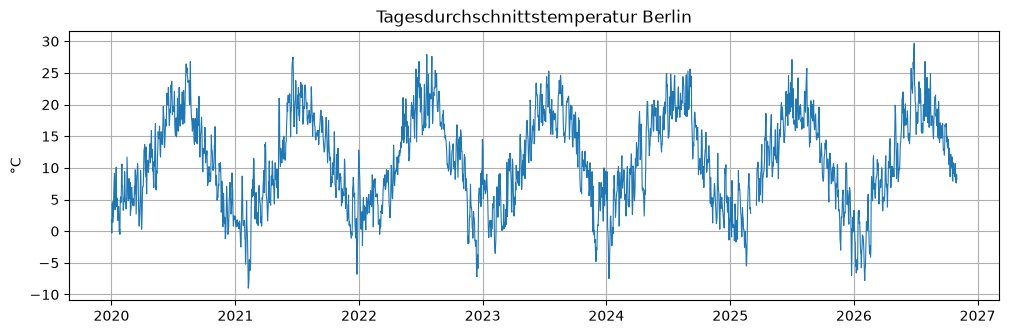

In [3]:
plt.figure(figsize=(12, 3.5))
plt.plot(df['datum'], df['temp_durch'], lw=0.8)
plt.title('Tagesdurchschnittstemperatur Berlin')
plt.ylabel('°C')
plt.grid(True)
plt.show()

## 3. Datenstruktur und Trainingsdaten erzeugen (Sliding Window)

Ein Modell lernt aus **Beispielen**: *Eingabe → richtige Antwort*. Aus der Zeitreihe bauen wir diese Beispiele mit einem „gleitenden Fenster“:

| Tag t-5 | t-4 | t-3 | t-2 | t-1 | Tag im Jahr von t | **Ziel: Temperatur an Tag t** |
|---|---|---|---|---|---|---|
| 1.8 | -0.3 | 4.3 | 4.1 | ... | ... | ... |

Jede Zeile ist ein Beispiel. Das Fenster wird Tag für Tag um eins verschoben, aus ~2500 Tagen entstehen also ~2500 Beispiele.

- **`X`** (Features): Matrix mit 6 Spalten (`t-5` … `t-1` und `tag_im_jahr`)
- **`y`** (Target): Vektor mit der Temperatur des zu prognostizierenden Tages

Der Tag im Jahr (`dayofyear`) bezieht sich auf den **Zieltag**, also den Tag, den wir vorhersagen. Schaltjahr-Tag 366 wird auf 365 begrenzt, damit der Wertebereich 1-365 bleibt.

In [4]:
ANZAHL_TAGE = 5

daten = pd.DataFrame({'datum': df['datum'], 'ziel': df['temp_durch']})

# shift(k) verschiebt die Reihe um k Tage nach unten: in Zeile t steht dann der Wert von t-k
for k in range(ANZAHL_TAGE, 0, -1):
    daten[f't-{k}'] = df['temp_durch'].shift(k)

daten['tag_im_jahr'] = daten['datum'].dt.day_of_year.clip(upper=365)

# Sicherstellen, dass das Fenster lückenlos ist: Zieltag und Tag t-5 müssen genau 5 Tage auseinander liegen
luecke = (daten['datum'] - daten['datum'].shift(ANZAHL_TAGE)).dt.days != ANZAHL_TAGE
daten = daten[~luecke]

# Zeilen mit fehlenden Werten (NaN) entfernen
daten = daten.dropna().reset_index(drop=True)

merkmale = [f't-{k}' for k in range(ANZAHL_TAGE, 0, -1)] + ['tag_im_jahr']
X = daten[merkmale]
y = daten['ziel']

print('Anzahl Trainingsbeispiele:', len(daten))
daten.head()

Anzahl Trainingsbeispiele: 2471


,datum,ziel,t-5,t-4,t-3,t-2,t-1,tag_im_jahr
0,2020-01-06,4.7,1.8,-0.3,4.3,4.1,1.4,6
1,2020-01-07,2.3,-0.3,4.3,4.1,1.4,4.7,7
2,2020-01-08,6.2,4.3,4.1,1.4,4.7,2.3,8
3,2020-01-09,8.1,4.1,1.4,4.7,2.3,6.2,9
4,2020-01-10,9.1,1.4,4.7,2.3,6.2,8.1,10


## 4. Aufteilen in Trainings- und Testdaten

Um die Genauigkeit ehrlich zu messen, testen wir das Modell mit Daten, die es **nie beim Training gesehen hat**.

Bei Zeitreihen mischen wir **nicht zufällig**, sondern teilen **zeitlich**: die Vergangenheit ist Training, die jüngste Zeit ist Test. Das entspricht dem echten Einsatz (aus der Vergangenheit die Zukunft vorhersagen). Ein zufälliges Mischen würde „schummeln“, da benachbarte Tage fast identisch sind.

- Training: bis einschließlich 2024
- Test: ab 2025

In [5]:
ist_train = daten['datum'] < '2025-01-01'

X_train, y_train = X[ist_train], y[ist_train]
X_test, y_test = X[~ist_train], y[~ist_train]
datum_test = daten.loc[~ist_train, 'datum']

print('Training:', len(X_train), 'Beispiele')
print('Test:    ', len(X_test), 'Beispiele')

Training: 1822 Beispiele
Test:     649 Beispiele


## 5. Fehlermaße und einfache Vergleichsmodelle (Baselines)

Eine Zahl wie „Fehler 2 °C“ sagt erst etwas aus, wenn man sie mit einfachen Methoden vergleicht. Deshalb definieren wir zuerst:

- **MAE** (mittlerer absoluter Fehler): durchschnittliche Abweichung in °C, leicht zu verstehen
- **RMSE**: wie MAE, bestraft große Ausreißer stärker
- **R²**: Anteil der Schwankung, den das Modell erklärt (1 = perfekt, 0 = nicht besser als der Mittelwert)

Baselines:
1. **Persistenz**: „Morgen ist es so wie heute“ (Wert von t-1)
2. **Ridge-Regression**: ein lineares Modell, das gewichtete Summen der Eingaben bildet

In [6]:
def bewerte(name, y_wahr, y_pred):
    return {
        'Modell': name,
        'MAE (°C)': mean_absolute_error(y_wahr, y_pred),
        'RMSE (°C)': np.sqrt(mean_squared_error(y_wahr, y_pred)),
        'R²': r2_score(y_wahr, y_pred),
    }

ergebnisse = []

# Baseline 1: Persistenz
ergebnisse.append(bewerte('Persistenz (gestern = morgen)', y_test, X_test['t-1']))

# Baseline 2: lineares Modell. Der StandardScaler bringt alle Eingaben auf Mittelwert 0 und Streuung 1.
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge.fit(X_train, y_train)
ergebnisse.append(bewerte('Lineare Regression (Ridge)', y_test, ridge.predict(X_test)))

pd.DataFrame(ergebnisse).round(2)

,Modell,MAE (°C),RMSE (°C),R²
0,Persistenz (gestern = morgen),1.73,2.23,0.91
1,Lineare Regression (Ridge),1.65,2.09,0.92


## 6. KI-Modell: neuronales Netz trainieren

Wir nutzen ein kleines **mehrschichtiges Perzeptron** (`MLPRegressor`, ein einfaches neuronales Netz):

- **Eingabeschicht:** 6 Werte (5 Temperaturen + Tag im Jahr)
- **2 versteckte Schichten** mit je 32 und 16 Neuronen (`ReLU`-Aktivierung), hier lernt das Netz nichtlineare Zusammenhänge
- **Ausgabe:** 1 Wert (Temperatur von morgen)

Wie wird trainiert? Das Netz startet mit zufälligen Gewichten, macht Vorhersagen auf den Trainingsdaten, misst den Fehler (quadratische Abweichung) und passt die Gewichte schrittweise an, um ihn zu verringern (Optimierer *Adam*). Dieser Vorgang wird über viele Durchläufe (*Epochen*) wiederholt.

Wichtige Einstellungen:
- **`StandardScaler`**: Neuronale Netze lernen deutlich besser, wenn alle Eingaben ähnliche Größenordnung haben (sonst dominiert der Tag im Jahr mit Werten bis 365 die Temperaturen um 10).
- **`early_stopping=True`**: 10 % der Trainingsdaten werden als Validierung abgezweigt; sobald sich der Fehler dort nicht mehr verbessert, stoppt das Training. Das verhindert *Overfitting* (Auswendiglernen).
- **`random_state`**: macht das Ergebnis reproduzierbar.

In [7]:
modell = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(32, 16),
        activation='relu',
        solver='adam',
        alpha=1e-3,
        max_iter=1000,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=42,
    ),
)
modell.fit(X_train, y_train)

mlp = modell[-1]
print('Trainings-Epochen bis zum Stopp:', mlp.n_iter_)

Trainings-Epochen bis zum Stopp: 209


Der Lernverlauf zeigt, wie der Trainingsfehler (Loss) über die Epochen sinkt. Flacht die Kurve ab, hat das Netz das Wesentliche gelernt.

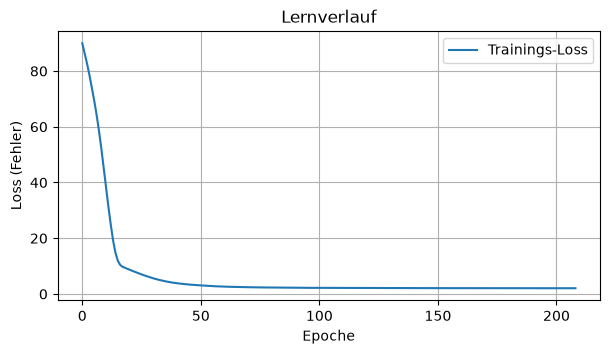

In [8]:
plt.figure(figsize=(7, 3.5))
plt.plot(mlp.loss_curve_, label='Trainings-Loss')
plt.xlabel('Epoche')
plt.ylabel('Loss (Fehler)')
plt.title('Lernverlauf')
plt.legend()
plt.grid(True)
plt.show()

## 7. Genauigkeit auf den Testdaten

Jetzt wird das Netz auf den **ungesehenen** Testdaten (2025 bis heute) geprüft und mit den Baselines verglichen.

In [9]:
y_pred = modell.predict(X_test)
ergebnisse.append(bewerte('Neuronales Netz (MLP)', y_test, y_pred))

tabelle = pd.DataFrame(ergebnisse).set_index('Modell').round(2)
tabelle

,MAE (°C),RMSE (°C),R²
Modell,,,
Persistenz (gestern = morgen),1.73,2.23,0.91
Lineare Regression (Ridge),1.65,2.09,0.92
Neuronales Netz (MLP),1.61,2.04,0.93


**Wie liest man das?** Der MAE gibt an, um wie viel °C die Prognose im Mittel danebenliegt. Ein Modell ist nur dann nützlich, wenn es besser ist als die Persistenz-Baseline. Ein Vorteil gegenüber der Persistenz entsteht, weil das Modell aus den letzten 5 Tagen den Trend sowie die Rückkehr zum saisonalen Mittel (über den Tag im Jahr) berücksichtigt.

Zur Veranschaulichung vergleichen wir Prognose und Messwert im Diagramm.

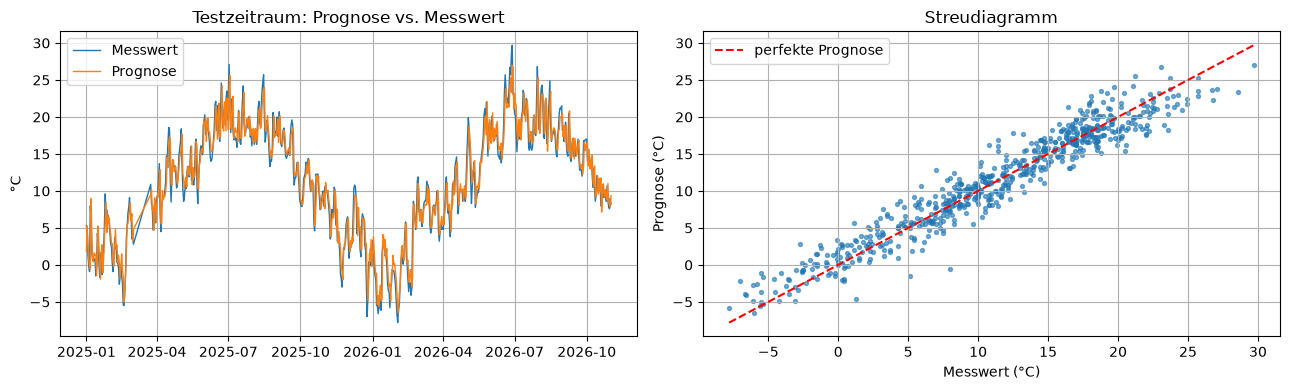

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(datum_test, y_test, label='Messwert', lw=1)
axes[0].plot(datum_test, y_pred, label='Prognose', lw=1)
axes[0].set_title('Testzeitraum: Prognose vs. Messwert')
axes[0].set_ylabel('°C')
axes[0].legend()
axes[0].grid(True)

axes[1].scatter(y_test, y_pred, s=8, alpha=0.6)
grenzen = [y_test.min(), y_test.max()]
axes[1].plot(grenzen, grenzen, 'r--', label='perfekte Prognose')
axes[1].set_xlabel('Messwert (°C)')
axes[1].set_ylabel('Prognose (°C)')
axes[1].set_title('Streudiagramm')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Punkte nahe der roten Diagonale sind gute Prognosen. Zusätzlich schauen wir uns die **Verteilung der Fehler** an: Ein guter Prognosefehler ist um 0 zentriert (kein systematisches Zu-warm/Zu-kalt).

Mittlerer Fehler (Bias): 0.15 °C
Anteil der Tage mit Fehler <= 2 °C: 69%
Anteil der Tage mit Fehler <= 3 °C: 86%


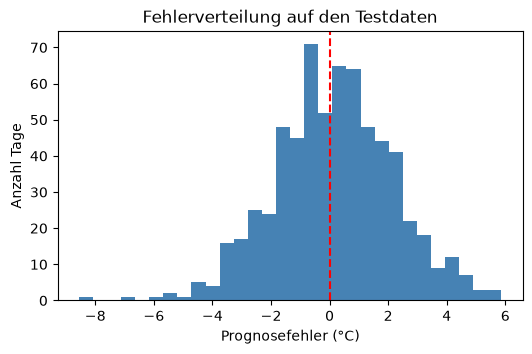

In [11]:
fehler = y_pred - y_test
print(f'Mittlerer Fehler (Bias): {fehler.mean():.2f} °C')
print(f'Anteil der Tage mit Fehler <= 2 °C: {(fehler.abs() <= 2).mean():.0%}')
print(f'Anteil der Tage mit Fehler <= 3 °C: {(fehler.abs() <= 3).mean():.0%}')

plt.figure(figsize=(6, 3.5))
plt.hist(fehler, bins=30, color='steelblue')
plt.axvline(0, color='r', ls='--')
plt.xlabel('Prognosefehler (°C)')
plt.ylabel('Anzahl Tage')
plt.title('Fehlerverteilung auf den Testdaten')
plt.show()

## 8. Erweitertes Modell: alle Wetterdaten der letzten 5 Tage

Bisher kannte das Netz nur die Durchschnittstemperaturen. Jetzt geben wir ihm **alle fünf Messgrößen** der letzten 5 Tage:
`temp_min`, `temp_max`, `temp_durch`, `niederschlagsmenge`, `sonnenstunden`. Das sind 5 Größen × 5 Tage + Tag im Jahr = **26 Eingangswerte**. Das Ziel bleibt unverändert: `temp_durch` des Folgetags.

**Damit die Ergebnisse vergleichbar sind**, bleibt alles andere gleich: derselbe Zieltag je Beispiel, dieselbe zeitliche Aufteilung (Training bis 2024, Test ab 2025), dieselbe Skalierung, dieselbe Netzarchitektur und dieselben Fehlermaße. Einziger Unterschied sind die zusätzlichen Eingaben.

**Schritt 1: Daten mit allen Spalten laden.** Wir lesen die CSV erneut, diesmal mit allen Wetterspalten.

In [12]:
GROESSEN = ['temp_min', 'temp_max', 'temp_durch', 'niederschlagsmenge', 'sonnenstunden']

df_voll = pd.read_csv('dwd_berlin_00403_20200101_20261101.csv', parse_dates=['datum'])
df_voll = df_voll.sort_values('datum').reset_index(drop=True)
df_voll[GROESSEN].describe().round(1)

,temp_min,temp_max,temp_durch,niederschlagsmenge,sonnenstunden
count,2481.0,2481.0,2481.0,2482.0,2481.0
mean,6.6,15.7,11.1,1.4,5.6
std,6.3,8.7,7.3,3.4,4.7
min,-12.2,-7.2,-9.0,0.0,0.0
25%,1.7,8.7,5.6,0.0,1.0
50%,6.7,15.8,10.9,0.0,5.1
75%,11.9,22.5,17.1,1.2,9.5
max,21.4,39.0,29.7,44.6,16.1


**Schritt 2: Sliding Window für alle Größen.** Wie in Abschnitt 3 verschieben wir jede Spalte um 1 bis 5 Tage (z. B. `sonnenstunden_t-3` = Sonnenstunden vor 3 Tagen). Danach übernehmen wir **nur die Zieltage, die auch im ersten Datensatz `daten` enthalten sind** (`merge` über das Datum). So sind Trainings- und Testbeispiele garantiert identisch zu denen der bisherigen Modelle, und der Vergleich ist fair.

In [13]:
erweitert = pd.DataFrame({'datum': df_voll['datum']})
for groesse in GROESSEN:
    for k in range(ANZAHL_TAGE, 0, -1):
        erweitert[f'{groesse}_t-{k}'] = df_voll[groesse].shift(k)

# Nur die Zieltage aus dem ersten Datensatz behalten (gleiche Beispiele, gleiche Reihenfolge)
daten_voll = daten[['datum', 'ziel', 'tag_im_jahr']].merge(erweitert, on='datum', how='left')

merkmale_voll = [c for c in erweitert.columns if c != 'datum'] + ['tag_im_jahr']
print('Fehlende Werte in den Eingaben:', int(daten_voll[merkmale_voll].isna().sum().sum()))
print('Anzahl Eingangswerte:', len(merkmale_voll))

X_voll = daten_voll[merkmale_voll]
X_voll_train, X_voll_test = X_voll[ist_train], X_voll[~ist_train]
assert (daten_voll['datum'] == daten['datum']).all()
daten_voll.head()

Fehlende Werte in den Eingaben: 0
Anzahl Eingangswerte: 26


,datum,ziel,tag_im_jahr,temp_min_t-5,temp_min_t-4,temp_min_t-3,temp_min_t-2,temp_min_t-1,temp_max_t-5,temp_max_t-4,...,niederschlagsmenge_t-5,niederschlagsmenge_t-4,niederschlagsmenge_t-3,niederschlagsmenge_t-2,niederschlagsmenge_t-1,sonnenstunden_t-5,sonnenstunden_t-4,sonnenstunden_t-3,sonnenstunden_t-2,sonnenstunden_t-1
0,2020-01-06,4.7,6,-2.8,-4.1,0.8,1.7,-1.4,5.0,6.2,...,0.0,0.0,4.4,3.0,0.0,2.9,7.5,0.0,0.0,2.1
1,2020-01-07,2.3,7,-4.1,0.8,1.7,-1.4,1.9,6.2,6.9,...,0.0,4.4,3.0,0.0,0.0,7.5,0.0,0.0,2.1,2.1
2,2020-01-08,6.2,8,0.8,1.7,-1.4,1.9,-2.1,6.9,5.6,...,4.4,3.0,0.0,0.0,0.2,0.0,0.0,2.1,2.1,0.0
3,2020-01-09,8.1,9,1.7,-1.4,1.9,-2.1,3.1,5.6,3.6,...,3.0,0.0,0.0,0.2,1.9,0.0,2.1,2.1,0.0,0.0
4,2020-01-10,9.1,10,-1.4,1.9,-2.1,3.1,7.0,3.6,7.3,...,0.0,0.0,0.2,1.9,5.3,2.1,2.1,0.0,0.0,0.0


**Schritt 3: Training.** Das Netz hat dieselben Einstellungen wie in Abschnitt 6 (Skalierung ist hier besonders wichtig, da Niederschlag in mm, Sonnenstunden und Temperaturen ganz unterschiedliche Größenordnungen haben). Als Zielwerte `y_train` verwenden wir die gleichen wie zuvor.

In [14]:
modell_voll = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(32, 16),
        activation='relu',
        solver='adam',
        alpha=1e-3,
        max_iter=1000,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=42,
    ),
)
modell_voll.fit(X_voll_train, y_train)
print('Trainings-Epochen bis zum Stopp:', modell_voll[-1].n_iter_)

Trainings-Epochen bis zum Stopp: 156


**Schritt 4: Vergleich auf den Testdaten.** Wir bewerten mit derselben Funktion `bewerte` und hängen das Ergebnis an die bisherige Tabelle an.

In [15]:
y_pred_voll = modell_voll.predict(X_voll_test)
ergebnisse.append(bewerte('Neuronales Netz (alle Wetterdaten)', y_test, y_pred_voll))

pd.DataFrame(ergebnisse).set_index('Modell').round(2)

,MAE (°C),RMSE (°C),R²
Modell,,,
Persistenz (gestern = morgen),1.73,2.23,0.91
Lineare Regression (Ridge),1.65,2.09,0.92
Neuronales Netz (MLP),1.61,2.04,0.93
Neuronales Netz (alle Wetterdaten),1.76,2.21,0.91


Zur Veranschaulichung zeigen wir beide neuronalen Netze im Testzeitraum und die Verteilung der Fehler.

Mittlerer Fehler (Bias): 0.01 °C
Anteil der Tage mit Fehler <= 2 °C: 63%
Anteil der Tage mit Fehler <= 3 °C: 82%


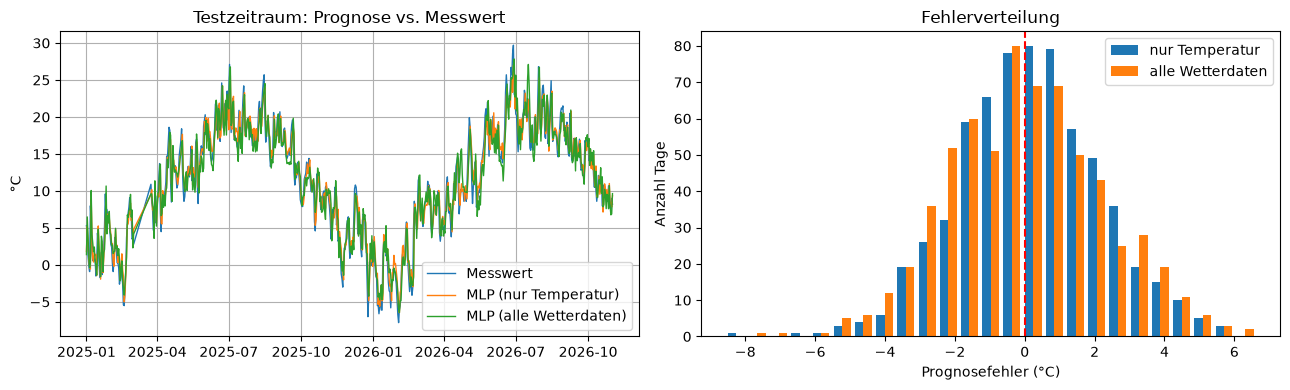

In [16]:
fehler_voll = y_pred_voll - y_test
print(f'Mittlerer Fehler (Bias): {fehler_voll.mean():.2f} °C')
print(f'Anteil der Tage mit Fehler <= 2 °C: {(fehler_voll.abs() <= 2).mean():.0%}')
print(f'Anteil der Tage mit Fehler <= 3 °C: {(fehler_voll.abs() <= 3).mean():.0%}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(datum_test, y_test, label='Messwert', lw=1)
axes[0].plot(datum_test, y_pred, label='MLP (nur Temperatur)', lw=1)
axes[0].plot(datum_test, y_pred_voll, label='MLP (alle Wetterdaten)', lw=1)
axes[0].set_title('Testzeitraum: Prognose vs. Messwert')
axes[0].set_ylabel('°C')
axes[0].legend()
axes[0].grid(True)

axes[1].hist([fehler, fehler_voll], bins=25, label=['nur Temperatur', 'alle Wetterdaten'])
axes[1].axvline(0, color='r', ls='--')
axes[1].set_xlabel('Prognosefehler (°C)')
axes[1].set_ylabel('Anzahl Tage')
axes[1].set_title('Fehlerverteilung')
axes[1].legend()
plt.tight_layout()
plt.show()

**Einordnung:** Ob die zusätzlichen Größen helfen, zeigt der Vergleich der MAE-/RMSE-Werte in der Tabelle oben. Mit 26 statt 6 Eingaben und nur 1822 Trainingsbeispielen kann das Netz leichter *überanpassen* (Auswendiglernen). Ein Gewinn ist daher nicht garantiert.

**Ergebnis:** Das Modell mit allen Wetterdaten schneidet auf den Testdaten *schlechter* ab (MAE 1,76 °C gegenüber 1,61 °C) und liegt etwa auf dem Niveau der Persistenz. Die zusätzlichen Größen enthalten kaum neue Information über die Temperatur von morgen (`temp_min`/`temp_max` hängen eng an `temp_durch`), vergrößern aber die Modellkomplexität. Mögliche Abhilfe: mehr Daten, stärkere Regularisierung (`alpha`), weniger Eingaben oder ein anderes Modell.

## 9. Einzelne Prognose erstellen

Zum Schluss nutzen wir das Modell wie im echten Einsatz: Wir nehmen die **letzten 5 Messwerte** aus den Daten und prognostizieren die Temperatur für den **Folgetag**. Der Tag im Jahr ist dabei der des Prognosetags.

In [17]:
letzte = df.dropna().tail(ANZAHL_TAGE)
prognose_tag = letzte['datum'].iloc[-1] + pd.Timedelta(days=1)

eingabe = pd.DataFrame([list(letzte['temp_durch']) + [min(prognose_tag.day_of_year, 365)]], columns=merkmale)
prognose = modell.predict(eingabe)[0]

print('Letzte 5 Tage:')
print(letzte.set_index(letzte['datum'].dt.date)['temp_durch'].to_string())
print(f'\nPrognose für {prognose_tag:%d.%m.%Y}: {prognose:.1f} °C')

Letzte 5 Tage:
datum
2026-10-28    8.8
2026-10-29    7.8
2026-10-30    7.6
2026-10-31    9.0
2026-11-01    8.2

Prognose für 02.11.2026: 7.8 °C


## Zusammenfassung und Ausblick

- Aus der Zeitreihe haben wir mit einem **Sliding Window** Trainingsbeispiele (5 Vortage + Tag im Jahr → morgen) erzeugt.
- Die Daten wurden **zeitlich** in Training und Test geteilt, um die Genauigkeit realistisch zu messen.
- Das neuronale Netz wurde mit den Baselines (Persistenz, lineare Regression) verglichen.

**Mögliche Verbesserungen:** mehr Jahre Daten, der Tag im Jahr als Kreis (`sin`/`cos`, damit Tag 365 und Tag 1 „benachbart“ sind), weitere Eingaben (Niederschlag, Sonnenstunden), andere Modelle (z. B. Gradient Boosting, LSTM).